import numpy as np


def inews(a="../nlpdat/inews/dev.txt"):
    a = np.loadtxt(a, "U", None, "_!_", usecols=(2, 3), encoding="utf-8").view("I").view("2H")[..., 0]
    a[:, -1] = ord("。")
    return a[a.astype("?")]


def toH(a):
    m = np.zeros(65536, "?")
    m[a] = 1
    m = m.nonzero()[0]
    print(len(m))
    M = np.empty(65536, "H")
    M[m] = np.arange(len(m), dtype="H")
    return M[a]


def toB(a):
    a = a[(0x4E00 <= a) & (a <= 0x9FA5)]
    m = np.zeros(65536, "I")
    np.add.at(m, a, 1)
    M = np.zeros(65536, "H")
    M[m.argpartition(-256)[-256:]] = np.arange(256, 512, dtype="H")
    a = M[a].view("2B")
    return a[a[:, 1].view("?"), 0]


a = np.concatenate((inews(), inews("../nlpdat/inews/test.txt"), inews("../nlpdat/inews/train.txt")))
a.tofile("inews.U")
toH(a).tofile("inews.7622")
toB(a).tofile("inews.B")

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
from torch.nn import *

torch.set_default_tensor_type(torch.cuda.FloatTensor)


class F(Module):
    def __init__(s, f, a=None):
        super().__init__()
        s.f = f
        s.a = a

    def forward(s, x):
        return s.f(x) if s.a is None else s.f(x, s.a)


class Enc(Sequential):
    def forward(s, x):
        while x.size(2) > 1:
            x = super().forward(x)
        return x[..., 0]


class EncDec(Sequential):
    def forward(s, x):
        Y = []
        for i in range(int(np.log2(x.size(2)))):
            x = s[0](x)
            y = s[1](x)
            for i in range(i + 1):
                y = s[2](y)
            Y.append(y)
        return torch.cat(Y)


class Add(Sequential):
    def forward(s, x):
        return sum((s(x) for s in s[1:]), s[0](x))


class Mean(Add):
    def forward(s, x):
        return super().forward(x) / len(s)


class Log:
    a = None

    def __init__(s, n=10):
        s.n = n

    def __call__(s, x):
        if s.a is None:
            s.a = np.array(x[None])
        else:
            s.a.resize((len(s.a) + 1, s.a.shape[1]), refcheck=0)
            s.a[-1] = x
        if not len(s.a) % s.n:
            plt.plot(s.a)
            clear_output(1)
            plt.show()

In [ ]:
a = torch.tensor(np.memmap("inews.B", "B")).unfold(0, 256, 1)
k = 512
m = Sequential(
    Embedding(256, k),
    F(lambda x: x.transpose(1, 2)),
    EncDec(
        Sequential(
            Add(
                Sequential(
                    Conv1d(k, k, 3, padding=1, bias=0),
                    BatchNorm1d(k, track_running_stats=0),
                    Hardswish(1),
                    Conv1d(k, k, 1, bias=0),
                ),
                Conv1d(k, k, 3, padding=1, bias=0),
            ),
            MaxPool1d(2),
        ),
        Sequential(
            Conv1d(k, k, 1, bias=0),
            BatchNorm1d(k, track_running_stats=0),
            Hardswish(1),
            Conv1d(k, k, 1),
        ),
        Sequential(
            Add(
                Sequential(
                    ConvTranspose1d(k, k, 3, 2, 1, 1, bias=0),
                    BatchNorm1d(k, track_running_stats=0),
                    Hardswish(1),
                ),
                ConvTranspose1d(k, k, 3, 2, 1, 1, bias=0),
            ),
        ),
    ),
    Conv1d(k, k, 1, bias=0),
    BatchNorm1d(k, track_running_stats=0),
    Hardswish(1),
    Conv1d(k, 256, 1),
)
o = torch.optim.Adam(m.parameters())
O = torch.optim.lr_scheduler.OneCycleLR(o, 0.001, 100000, pct_start=0.01, div_factor=9, final_div_factor=99)
log = Log()
for t in range(O.total_steps // 100):
    for t in range(100):
        y = a[torch.randint(len(a), (4,))].long()
        x = m(y).unflatten(0, (int(np.log2(a.size(1))), -1))
        functional.cross_entropy(x.transpose(1, 2), y.expand(len(x), -1, -1)).backward()
        o.step()
        o.zero_grad()
        O.step()
    log((x.argmax(2) == y).float().mean((1, 2)).cpu())

64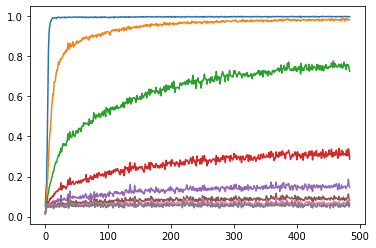
256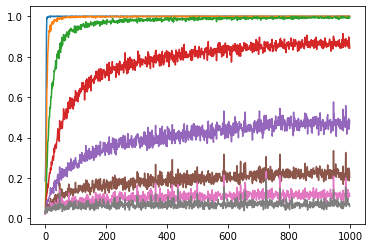
512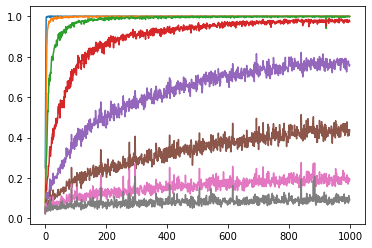

In [ ]:
class DecR(Sequential):
    def forward(s, x):
        x = x[0]
        for i, x in enumerate(x, 1):
            yield s[1](s[0](torch.linspace(0, 1, i)[:, None, None].expand(-1, len(x), 1), x[None])[0])


a = torch.tensor(np.memmap("inews.B", "B")).unfold(0, 16, 1)
k = 16
m = Sequential(
    Embedding(256, k),
    GRU(k, k),
    DecR(
        GRU(1, k),
        Sequential(
            Linear(k, k),
            Hardswish(1),
            Linear(k, 256),
        ),
    ),
)
o = torch.optim.Adam(m.parameters())
O = torch.optim.lr_scheduler.OneCycleLR(o, 0.01, 100000, pct_start=0.01, div_factor=9, final_div_factor=99)
log = Log(1)
for x in range(O.total_steps // 1000):
    for x in range(1000):
        y = a[torch.randint(len(a), (512,))].T.long()
        if x < 999:
            x = m(y)
        else:
            x = list(m(y))
            log([(x.argmax(2) == y[:i]).sum().item() / x.shape[:2].numel() for i, x in enumerate(x, 1)])
        sum(functional.cross_entropy(x.transpose(1, 2), y[:i]) * i for i, x in enumerate(x, 1)).backward()
        o.step()
        o.zero_grad()
        O.step()

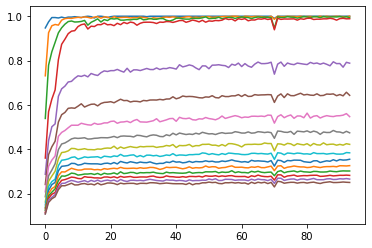

In [ ]:
a = torch.tensor(np.memmap("inews.B", "B")).unfold(0, 8, 1)
k = 16
m = Sequential(
    Embedding(256, k),
    F(lambda x: x.transpose(1, 2)),
    EncDec(
        Sequential(
            Add(
                Sequential(
                    Conv1d(k, k, 3, padding=1, bias=0),
                    BatchNorm1d(k, track_running_stats=0),
                    Hardswish(1),
                    Conv1d(k, k, 3, padding=1, bias=0),
                    BatchNorm1d(k, track_running_stats=0),
                    Hardswish(1),
                    Conv1d(k, k, 3, padding=1, bias=0),
                ),
                Sequential(
                    Conv1d(k, k, 3, padding=1, bias=0),
                    BatchNorm1d(k, track_running_stats=0),
                    Hardswish(1),
                    Conv1d(k, k, 3, padding=1, bias=0),
                ),
                Conv1d(k, k, 3, padding=1, bias=0),
            ),
            MaxPool1d(2),
        ),
        Sequential(
            Conv1d(k, k, 1, bias=0),
            BatchNorm1d(k, track_running_stats=0),
            Hardswish(1),
            Conv1d(k, k, 1),
        ),
        Sequential(
            F(lambda x: x.repeat_interleave(2, 2)),
            Add(
                Sequential(
                    Conv1d(k, k, 3, padding=1, bias=0),
                    # ConvTranspose1d(k, k, 3, 2, 1, 1, bias=0),
                    BatchNorm1d(k, track_running_stats=0),
                    Hardswish(1),
                    Conv1d(k, k, 3, padding=1, bias=0),
                    BatchNorm1d(k, track_running_stats=0),
                    Hardswish(1),
                    Conv1d(k, k, 3, padding=1, bias=0),
                ),
                Sequential(
                    Conv1d(k, k, 3, padding=1, bias=0),
                    # ConvTranspose1d(k, k, 3, 2, 1, 1, bias=0),
                    BatchNorm1d(k, track_running_stats=0),
                    Hardswish(1),
                    Conv1d(k, k, 3, padding=1, bias=0),
                ),
                Conv1d(k, k, 3, padding=1, bias=0),
                # ConvTranspose1d(k, k, 3, 2, 1, 1, bias=0),
            ),
        ),
    ),
    Conv1d(k, 256, 1, bias=0),
    BatchNorm1d(256, track_running_stats=0),
    Hardswish(1),
    Conv1d(256, 256, 1),
)
o = torch.optim.Adam(m.parameters())
O = torch.optim.lr_scheduler.OneCycleLR(o, 0.001, 50000, pct_start=0.01, div_factor=9, final_div_factor=99)
log = Log(1)
for x in range(O.total_steps // 500):
    for x in range(500):
        y = a[torch.randint(len(a), (1024,))].long()
        x = m(y).unflatten(0, (int(np.log2(a.size(1))), -1))
        functional.cross_entropy(x.transpose(1, 2), y.expand(len(x), -1, -1)).backward()
        o.step()
        o.zero_grad()
        O.step()
    log((x.argmax(2) == y).float().mean((1, 2)).cpu())

In [ ]:
a = torch.tensor(np.memmap("inews.B", "B")).unfold(0, 16, 1)
k = 16
m = Sequential(
    Embedding(256, k),
    F(lambda x: x.transpose(1, 2)),
    EncDec(
        Sequential(
            Add(
                Sequential(
                    Conv1d(k, k, 3, padding=1, bias=0),
                    BatchNorm1d(k, track_running_stats=0),
                    Hardswish(1),
                    Conv1d(k, k, 3, padding=1, bias=0),
                    BatchNorm1d(k, track_running_stats=0),
                    Hardswish(1),
                    Conv1d(k, k, 3, padding=1, bias=0),
                ),
                Sequential(
                    Conv1d(k, k, 3, padding=1, bias=0),
                    BatchNorm1d(k, track_running_stats=0),
                    Hardswish(1),
                    Conv1d(k, k, 3, padding=1, bias=0),
                ),
                Conv1d(k, k, 3, padding=1, bias=0),
            ),
            MaxPool1d(2),
        ),
        Sequential(
            Conv1d(k, k, 1, bias=0),
            BatchNorm1d(k, track_running_stats=0),
            Hardswish(1),
            Conv1d(k, k, 1),
        ),
        Sequential(
            F(lambda x: x.repeat_interleave(2, 2)),
            Add(
                Sequential(
                    Conv1d(k, k, 3, padding=1, bias=0),
                    # ConvTranspose1d(k, k, 3, 2, 1, 1, bias=0),
                    BatchNorm1d(k, track_running_stats=0),
                    Hardswish(1),
                    Conv1d(k, k, 3, padding=1, bias=0),
                    BatchNorm1d(k, track_running_stats=0),
                    Hardswish(1),
                    Conv1d(k, k, 3, padding=1, bias=0),
                ),
                Sequential(
                    Conv1d(k, k, 3, padding=1, bias=0),
                    # ConvTranspose1d(k, k, 3, 2, 1, 1, bias=0),
                    BatchNorm1d(k, track_running_stats=0),
                    Hardswish(1),
                    Conv1d(k, k, 3, padding=1, bias=0),
                ),
                Conv1d(k, k, 3, padding=1, bias=0),
                # ConvTranspose1d(k, k, 3, 2, 1, 1, bias=0),
            ),
        ),
    ),
    Conv1d(k, 256, 1, bias=0),
    BatchNorm1d(256, track_running_stats=0),
    Hardswish(1),
    Conv1d(256, 256, 1),
)
o = torch.optim.Adam(m.parameters())
O = torch.optim.lr_scheduler.OneCycleLR(o, 0.001, 100000, pct_start=0.01, div_factor=9, final_div_factor=99)
log = Log()
for t in range(O.total_steps // 1000):
    for t in range(1, 1001):
        y = a[torch.randint(len(a), (1024,))].long()
        x = m(y).unflatten(0, (int(np.log2(a.size(1))), -1))
        if t % 100:
            t = functional.cross_entropy(x.transpose(1, 2), y.expand(len(x), -1, -1))
        else:
            t = functional.cross_entropy(x.transpose(1, 2), y.expand(len(x), -1, -1), reduction="none").mean((1, 2))
            with torch.no_grad():
                log(((8 - t / np.log(2)) * torch.tensor((2.0, 4, 8, 16))).cpu())
            t = t.mean()
        t.backward()
        o.step()
        o.zero_grad()
        O.step()